Enter gate (X, Y, Z, H, S, T):  H
Enter initial state (0, 1, +, -):  0


H gate matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

Initial state |0>:
1.0000|0> + 0.0000|1>

State after H gate:
0.7071|0> + 0.7071|1>

P(0) = 0.5000
P(1) = 0.5000


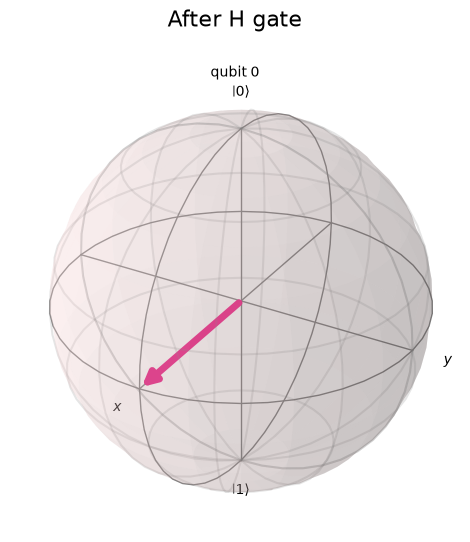

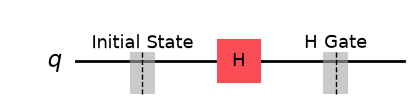

In [1]:
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_bloch_multivector
from IPython.display import display
import numpy as np

# 1. User input
gate = input("Enter gate (X, Y, Z, H, S, T): ").strip().upper()
start = input("Enter initial state (0, 1, +, -): ").strip()

if gate not in ["X", "Y", "Z", "H", "S", "T"]:
    raise ValueError("Enter one of X, Y, Z, H, S, T.")

if start not in ["0", "1", "+", "-"]:
    raise ValueError("Enter one of 0, 1, +, -.")

# 2. Format complex amplitudes
def format_amplitude(value):
    real = value.real
    imag = value.imag

    if abs(imag) < 1e-8:
        return f"{real:.4f}"

    if abs(real) < 1e-8:
        return f"{imag:.4f}j"

    sign = "+" if imag >= 0 else "-"
    return f"{real:.4f} {sign} {abs(imag):.4f}j"

# 3. Create circuit
q = QuantumRegister(1, 'q')
qc = QuantumCircuit(q)

# 4. Prepare initial state
if start == "1":
    qc.x(q[0])
elif start == "+":
    qc.h(q[0])
elif start == "-":
    qc.x(q[0])
    qc.h(q[0])

qc.barrier(label="Initial State")

sv_before = Statevector(qc)

# 5. Apply the chosen gate
getattr(qc, gate.lower())(q[0])
qc.barrier(label=f"{gate} Gate")

sv_after = Statevector(qc)

# 6. Gate matrix
gate_circuit = QuantumCircuit(1)
getattr(gate_circuit, gate.lower())(0)

print(f"{gate} gate matrix:")
print(np.round(Operator(gate_circuit).data, 4))

# 7. State before and after
print(f"\nInitial state |{start}>:")
print(f"{format_amplitude(sv_before.data[0])}|0> + {format_amplitude(sv_before.data[1])}|1>")

print(f"\nState after {gate} gate:")
print(f"{format_amplitude(sv_after.data[0])}|0> + {format_amplitude(sv_after.data[1])}|1>")

print(f"\nP(0) = {abs(sv_after.data[0])**2:.4f}")
print(f"P(1) = {abs(sv_after.data[1])**2:.4f}")

# 8. Bloch sphere after the gate
display(plot_bloch_multivector(sv_after, title=f"After {gate} gate"))

# 9. Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_2_SingleQubitGates.png", dpi=300, bbox_inches="tight")